In [1]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from scipy import stats

In [2]:
hypotheses = pd.read_csv('/datasets/hypotheses_us.csv', sep=';')
orders = pd.read_csv('/datasets/orders_us.csv')
visits = pd.read_csv('/datasets/visits_us.csv')

In [3]:
display(hypotheses.head())
display(orders.head())
display(visits.head())

,Hypothesis,Reach,Impact,Confidence,Effort
0,Add two new channels for attracting traffic. T...,3,10,8,6
1,Launch your own delivery service. This will sh...,2,5,4,10
2,Add product recommendation blocks to the store...,8,3,7,3
3,Change the category structure. This will incre...,8,3,3,8
4,Change the background color on the main page. ...,3,1,1,1


,transactionId,visitorId,date,revenue,group
0,3667963787,3312258926,2019-08-15,30.4,B
1,2804400009,3642806036,2019-08-15,15.2,B
2,2961555356,4069496402,2019-08-15,10.2,A
3,3797467345,1196621759,2019-08-15,155.1,B
4,2282983706,2322279887,2019-08-15,40.5,B


,date,group,visits
0,2019-08-01,A,719
1,2019-08-02,A,619
2,2019-08-03,A,507
3,2019-08-04,A,717
4,2019-08-05,A,756


In [4]:
hypotheses.info()

orders.info()

visits.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9 entries, 0 to 8
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype 
---  ------      --------------  ----- 
 0   Hypothesis  9 non-null      object
 1   Reach       9 non-null      int64 
 2   Impact      9 non-null      int64 
 3   Confidence  9 non-null      int64 
 4   Effort      9 non-null      int64 
dtypes: int64(4), object(1)
memory usage: 488.0+ bytes
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1197 entries, 0 to 1196
Data columns (total 5 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   transactionId  1197 non-null   int64  
 1   visitorId      1197 non-null   int64  
 2   date           1197 non-null   object 
 3   revenue        1197 non-null   float64
 4   group          1197 non-null   object 
dtypes: float64(1), int64(2), object(2)
memory usage: 46.9+ KB
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 62 entries, 0 to 61
Data columns (tota

In [5]:
for name, df in zip(
    ['Hypotheses', 'Orders', 'Visits'],
    [hypotheses, orders, visits]
):
    print(f'\n{name}')
    print('-' * 40)
    print('Valores ausentes:')
    print(df.isna().sum())
    print('\nDuplicatas:', df.duplicated().sum())


Hypotheses
----------------------------------------
Valores ausentes:
Hypothesis    0
Reach         0
Impact        0
Confidence    0
Effort        0
dtype: int64

Duplicatas: 0

Orders
----------------------------------------
Valores ausentes:
transactionId    0
visitorId        0
date             0
revenue          0
group            0
dtype: int64

Duplicatas: 0

Visits
----------------------------------------
Valores ausentes:
date      0
group     0
visits    0
dtype: int64

Duplicatas: 0


In [6]:
hypotheses.columns = hypotheses.columns.str.lower()

hypotheses

,hypothesis,reach,impact,confidence,effort
0,Add two new channels for attracting traffic. T...,3,10,8,6
1,Launch your own delivery service. This will sh...,2,5,4,10
2,Add product recommendation blocks to the store...,8,3,7,3
3,Change the category structure. This will incre...,8,3,3,8
4,Change the background color on the main page. ...,3,1,1,1
5,Add a customer review page. This will increase...,3,2,2,3
6,Show banners with current offers and sales on ...,5,3,8,3
7,Add a subscription form to all the main pages....,10,7,8,5
8,Launch a promotion that gives users discounts ...,1,9,9,5


In [7]:
hypotheses['ice'] = (
    hypotheses['impact']
    * hypotheses['confidence']
    / hypotheses['effort']
)

hypotheses[
    ['hypothesis', 'ice']
].sort_values(
    by='ice',
    ascending=False
)

,hypothesis,ice
8,Launch a promotion that gives users discounts ...,16.200000
0,Add two new channels for attracting traffic. T...,13.333333
7,Add a subscription form to all the main pages....,11.200000
6,Show banners with current offers and sales on ...,8.000000
2,Add product recommendation blocks to the store...,7.000000
1,Launch your own delivery service. This will sh...,2.000000
5,Add a customer review page. This will increase...,1.333333
3,Change the category structure. This will incre...,1.125000
4,Change the background color on the main page. ...,1.000000


In [8]:
hypotheses['rice'] = (
    hypotheses['reach']
    * hypotheses['impact']
    * hypotheses['confidence']
    / hypotheses['effort']
)

hypotheses[
    ['hypothesis', 'rice']
].sort_values(
    by='rice',
    ascending=False
)

,hypothesis,rice
7,Add a subscription form to all the main pages....,112.0
2,Add product recommendation blocks to the store...,56.0
0,Add two new channels for attracting traffic. T...,40.0
6,Show banners with current offers and sales on ...,40.0
8,Launch a promotion that gives users discounts ...,16.2
3,Change the category structure. This will incre...,9.0
1,Launch your own delivery service. This will sh...,4.0
5,Add a customer review page. This will increase...,4.0
4,Change the background color on the main page. ...,3.0


In [9]:
comparison = hypotheses[
    [
        'hypothesis',
        'reach',
        'impact',
        'confidence',
        'effort',
        'ice',
        'rice'
    ]
].sort_values(
    by='rice',
    ascending=False
)

comparison

,hypothesis,reach,impact,confidence,effort,ice,rice
7,Add a subscription form to all the main pages....,10,7,8,5,11.200000,112.0
2,Add product recommendation blocks to the store...,8,3,7,3,7.000000,56.0
0,Add two new channels for attracting traffic. T...,3,10,8,6,13.333333,40.0
6,Show banners with current offers and sales on ...,5,3,8,3,8.000000,40.0
8,Launch a promotion that gives users discounts ...,1,9,9,5,16.200000,16.2
3,Change the category structure. This will incre...,8,3,3,8,1.125000,9.0
1,Launch your own delivery service. This will sh...,2,5,4,10,2.000000,4.0
5,Add a customer review page. This will increase...,3,2,2,3,1.333333,4.0
4,Change the background color on the main page. ...,3,1,1,1,1.000000,3.0


In [10]:
ice_rank = hypotheses[
    ['hypothesis', 'ice']
].sort_values(
    by='ice',
    ascending=False
).reset_index(drop=True)

rice_rank = hypotheses[
    ['hypothesis', 'rice']
].sort_values(
    by='rice',
    ascending=False
).reset_index(drop=True)

print('Ranking ICE')
display(ice_rank)

print('Ranking RICE')
display(rice_rank)

Ranking ICE


,hypothesis,ice
0,Launch a promotion that gives users discounts ...,16.200000
1,Add two new channels for attracting traffic. T...,13.333333
2,Add a subscription form to all the main pages....,11.200000
3,Show banners with current offers and sales on ...,8.000000
4,Add product recommendation blocks to the store...,7.000000
5,Launch your own delivery service. This will sh...,2.000000
6,Add a customer review page. This will increase...,1.333333
7,Change the category structure. This will incre...,1.125000
8,Change the background color on the main page. ...,1.000000


Ranking RICE


,hypothesis,rice
0,Add a subscription form to all the main pages....,112.0
1,Add product recommendation blocks to the store...,56.0
2,Add two new channels for attracting traffic. T...,40.0
3,Show banners with current offers and sales on ...,40.0
4,Launch a promotion that gives users discounts ...,16.2
5,Change the category structure. This will incre...,9.0
6,Launch your own delivery service. This will sh...,4.0
7,Add a customer review page. This will increase...,4.0
8,Change the background color on the main page. ...,3.0


Conclusão da priorização de hipóteses

Ao comparar os frameworks ICE e RICE, observamos mudanças significativas na ordem de prioridade das hipóteses.

Pelo método ICE, a hipótese com maior prioridade foi **"Launch a promotion that gives users discounts..."**, com pontuação de 16.2. Essa hipótese apresentou uma combinação forte de impacto, confiança e esforço relativamente baixo.

Ao aplicar o framework RICE, a hipótese mais prioritária passou a ser **"Add a subscription form to all the main pages..."**, com pontuação de 112. Essa mudança ocorreu porque o RICE inclui a variável Reach (alcance), que considera quantos usuários podem ser afetados pela implementação da hipótese.

A hipótese relacionada à criação de um formulário de inscrição em todas as páginas principais possui um alcance maior, fazendo com que sua pontuação aumente significativamente quando comparada ao cálculo do ICE. Da mesma forma, hipóteses como a adição de blocos de recomendação de produtos e a criação de novos canais de aquisição de tráfego ganharam posições no ranking devido ao potencial de alcançar mais usuários.

Portanto, para a tomada de decisão do negócio, o framework RICE apresenta uma visão mais completa, pois considera não apenas o impacto esperado e a facilidade de implementação, mas também a quantidade de usuários que podem ser beneficiados pela mudança.


In [11]:
orders.head()

,transactionId,visitorId,date,revenue,group
0,3667963787,3312258926,2019-08-15,30.4,B
1,2804400009,3642806036,2019-08-15,15.2,B
2,2961555356,4069496402,2019-08-15,10.2,A
3,3797467345,1196621759,2019-08-15,155.1,B
4,2282983706,2322279887,2019-08-15,40.5,B


In [12]:
visits.head()

,date,group,visits
0,2019-08-01,A,719
1,2019-08-02,A,619
2,2019-08-03,A,507
3,2019-08-04,A,717
4,2019-08-05,A,756


In [13]:
orders['date'] = pd.to_datetime(orders['date'])

visits['date'] = pd.to_datetime(visits['date'])

In [14]:
users_a = orders[orders['group'] == 'A']['visitorId']

users_b = orders[orders['group'] == 'B']['visitorId']

ab_users = np.intersect1d(users_a, users_b)

len(ab_users)

58

In [15]:
orders_filtered = orders[~orders['visitorId'].isin(ab_users)]

In [16]:
orders_filtered.info()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 1016 entries, 0 to 1196
Data columns (total 5 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   transactionId  1016 non-null   int64         
 1   visitorId      1016 non-null   int64         
 2   date           1016 non-null   datetime64[ns]
 3   revenue        1016 non-null   float64       
 4   group          1016 non-null   object        
dtypes: datetime64[ns](1), float64(1), int64(2), object(1)
memory usage: 47.6+ KB


In [17]:
dates_groups = orders_filtered[['date', 'group']].drop_duplicates()

cumulative_orders = dates_groups.apply(
    lambda x: orders_filtered[
        (orders_filtered['date'] <= x['date']) &
        (orders_filtered['group'] == x['group'])
    ].agg({
        'date': 'max',
        'group': 'max',
        'transactionId': 'nunique',
        'visitorId': 'nunique',
        'revenue': 'sum'
    }),
    axis=1
)

cumulative_orders.columns = [
    'date',
    'group',
    'orders',
    'buyers',
    'revenue'
]

cumulative_orders.head()

,date,group,orders,buyers,revenue
0,2019-08-15,B,289,284,31033.2
7,2019-08-15,A,241,228,26622.5
45,2019-08-16,A,259,246,28221.6
47,2019-08-16,B,307,302,32840.2
55,2019-08-01,A,23,19,2266.6


In [18]:
cumulative_revenue_A = cumulative_orders[
    cumulative_orders['group'] == 'A'
]

cumulative_revenue_B = cumulative_orders[
    cumulative_orders['group'] == 'B'
]

In [19]:
cumulative_revenue_A = cumulative_revenue_A.sort_values(by='date')

cumulative_revenue_B = cumulative_revenue_B.sort_values(by='date')

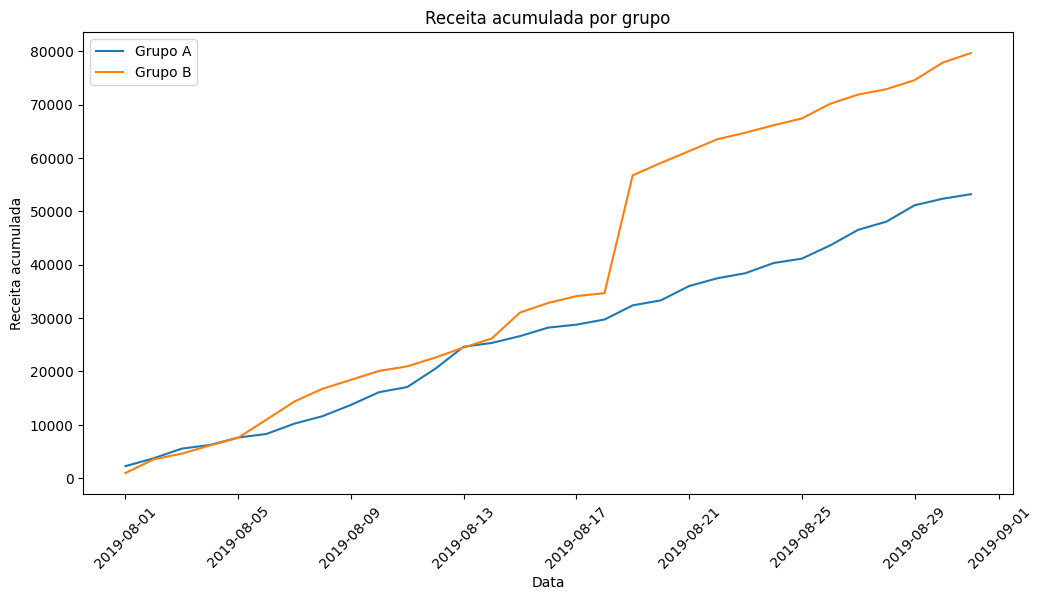

In [20]:
plt.figure(figsize=(12, 6))

plt.plot(
    cumulative_revenue_A['date'],
    cumulative_revenue_A['revenue'],
    label='Grupo A'
)

plt.plot(
    cumulative_revenue_B['date'],
    cumulative_revenue_B['revenue'],
    label='Grupo B'
)

plt.title('Receita acumulada por grupo')
plt.xlabel('Data')
plt.ylabel('Receita acumulada')

plt.legend()

plt.xticks(rotation=45)

plt.show()

Conclusão — Receita acumulada por grupo

O gráfico de receita acumulada mostra que o grupo B apresentou uma receita acumulada superior ao grupo A durante o período analisado.

Inicialmente, os dois grupos apresentaram comportamentos semelhantes, com as linhas de receita acumulada próximas entre si. Entretanto, a partir de aproximadamente 17/08/2019, observa-se um aumento significativo na distância entre os grupos, causado por um pico de receita no grupo B.

Esse crescimento repentino sugere a possibilidade de que o grupo B tenha recebido um ou mais pedidos de valor elevado nessa data, o que pode ter influenciado a diferença entre os grupos. Portanto, embora o grupo B apresente uma receita acumulada maior, é necessário investigar a presença de pedidos fora do padrão antes de concluir que a diferença representa uma melhoria real causada pelo teste.


In [21]:
cumulative_revenue_A['avg_order_value'] = (
    cumulative_revenue_A['revenue'] /
    cumulative_revenue_A['orders']
)

cumulative_revenue_B['avg_order_value'] = (
    cumulative_revenue_B['revenue'] /
    cumulative_revenue_B['orders']
)

cumulative_revenue_A.head()

,date,group,orders,buyers,revenue,avg_order_value
55,2019-08-01,A,23,19,2266.6,98.547826
175,2019-08-02,A,42,36,3734.9,88.926190
291,2019-08-03,A,66,60,5550.1,84.092424
499,2019-08-04,A,77,71,6225.6,80.851948
719,2019-08-05,A,99,92,7623.6,77.006061


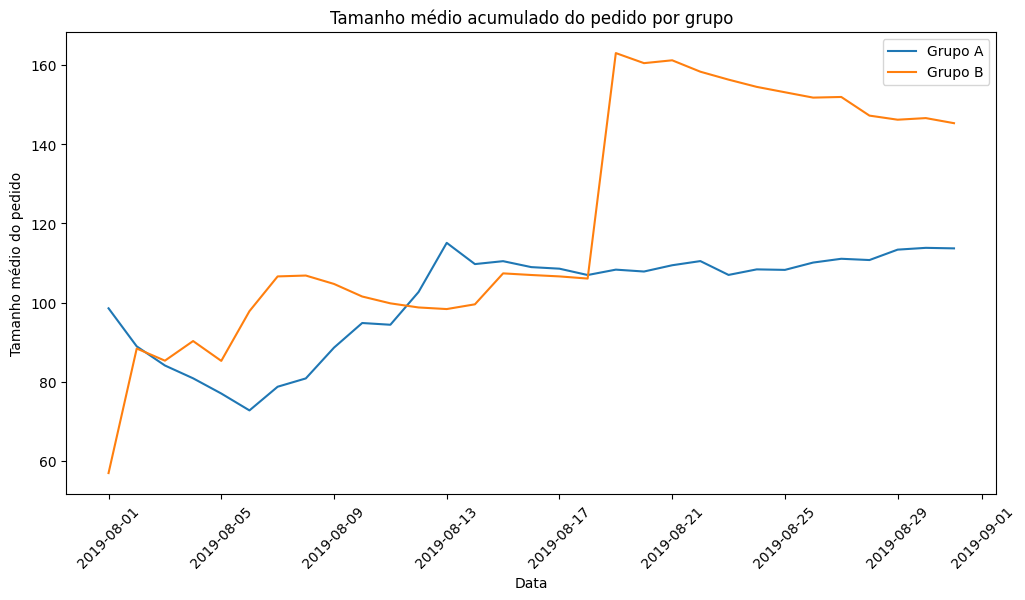

In [22]:
plt.figure(figsize=(12, 6))

plt.plot(
    cumulative_revenue_A['date'],
    cumulative_revenue_A['avg_order_value'],
    label='Grupo A'
)

plt.plot(
    cumulative_revenue_B['date'],
    cumulative_revenue_B['avg_order_value'],
    label='Grupo B'
)

plt.title('Tamanho médio acumulado do pedido por grupo')
plt.xlabel('Data')
plt.ylabel('Tamanho médio do pedido')

plt.legend()

plt.xticks(rotation=45)

plt.show()

Conclusão — Tamanho médio acumulado do pedido

O gráfico do tamanho médio acumulado do pedido mostra que o grupo B apresentou um valor superior ao grupo A ao longo do teste.

No início do período, observamos uma variação mais acentuada nos valores médios, especialmente no primeiro dia do teste, quando a quantidade de pedidos acumulados ainda era pequena. Por esse motivo, esse comportamento inicial pode ser resultado de oscilações naturais e não representa necessariamente uma tendência.

A partir de aproximadamente 17/08/2019, observa-se um aumento significativo na diferença entre os grupos, com o grupo B apresentando um pico no tamanho médio dos pedidos. Esse comportamento está relacionado ao aumento da receita acumulada observado anteriormente e pode indicar a influência de pedidos de valor elevado.

Portanto, embora o grupo B apresente um ticket médio acumulado maior, é necessário analisar possíveis valores atípicos antes de concluir que o resultado representa uma melhoria consistente.


In [23]:
merged_avg_order_value = cumulative_revenue_A.merge(
    cumulative_revenue_B,
    on='date',
    suffixes=['_A', '_B']
)

merged_avg_order_value['relative_difference'] = (
    merged_avg_order_value['avg_order_value_B'] /
    merged_avg_order_value['avg_order_value_A']
) - 1

merged_avg_order_value.head()

,date,group_A,orders_A,buyers_A,revenue_A,avg_order_value_A,group_B,orders_B,buyers_B,revenue_B,avg_order_value_B,relative_difference
0,2019-08-01,A,23,19,2266.6,98.547826,B,17,17,967.2,56.894118,-0.422675
1,2019-08-02,A,42,36,3734.9,88.926190,B,40,39,3535.3,88.382500,-0.006114
2,2019-08-03,A,66,60,5550.1,84.092424,B,54,53,4606.9,85.312963,0.014514
3,2019-08-04,A,77,71,6225.6,80.851948,B,68,66,6138.5,90.272059,0.116511
4,2019-08-05,A,99,92,7623.6,77.006061,B,89,87,7587.8,85.256180,0.107136


In [24]:
merged_avg_order_value = merged_avg_order_value.sort_values(by='date')

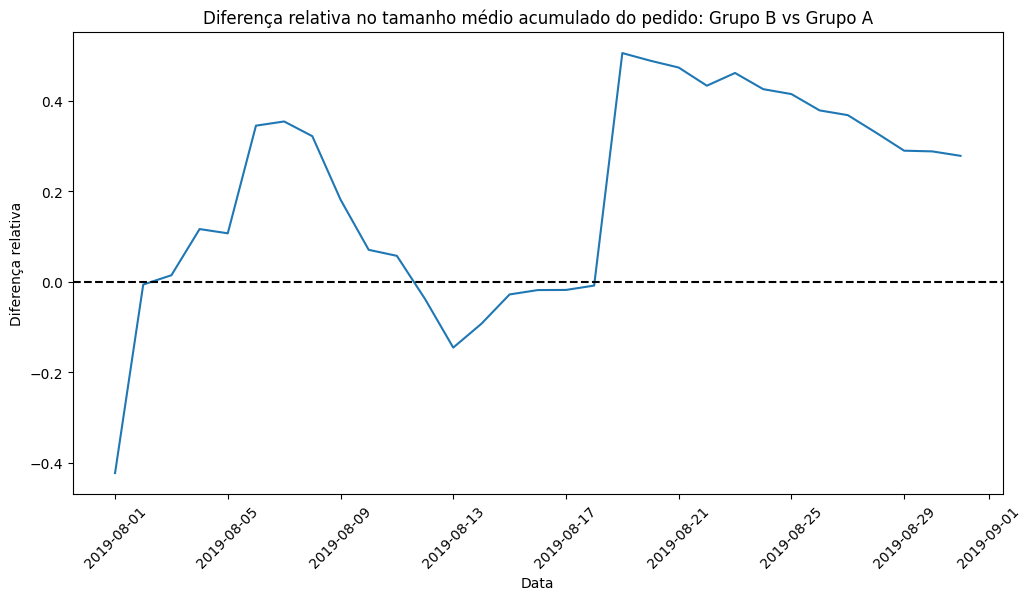

In [25]:
plt.figure(figsize=(12, 6))

plt.plot(
    merged_avg_order_value['date'],
    merged_avg_order_value['relative_difference']
)

plt.axhline(
    y=0,
    color='black',
    linestyle='--'
)

plt.title(
    'Diferença relativa no tamanho médio acumulado do pedido: Grupo B vs Grupo A'
)

plt.xlabel('Data')

plt.ylabel('Diferença relativa')

plt.xticks(rotation=45)

plt.show()

Conclusão — Diferença relativa no tamanho médio acumulado do pedido

O gráfico da diferença relativa no tamanho médio acumulado do pedido compara o desempenho do grupo B em relação ao grupo A ao longo do teste.

No início do experimento, o grupo B apresentou um tamanho médio de pedido inferior ao grupo A, ficando abaixo da linha de referência de 0. Durante os primeiros dias, essa diferença diminuiu e os valores se aproximaram entre os grupos.

Entre aproximadamente 09/08 e 13/08, observamos novamente uma queda na diferença relativa, indicando que o grupo B voltou a apresentar um desempenho inferior temporariamente. A partir de 17/08, ocorre uma mudança significativa no comportamento, com um aumento expressivo da diferença relativa em favor do grupo B.

Esse pico sugere que alguns pedidos de valor elevado podem ter influenciado o resultado do grupo B. Portanto, apesar de o grupo B apresentar vantagem no tamanho médio acumulado do pedido ao final do teste, ainda é necessário investigar possíveis valores atípicos antes de concluir que a diferença é causada pela alteração testada.


In [26]:
daily_orders = orders_filtered.groupby(
    ['date', 'group']
).agg({
    'transactionId': 'nunique'
}).reset_index()

daily_orders.columns = [
    'date',
    'group',
    'orders'
]

daily_orders.head()

,date,group,orders
0,2019-08-01,A,23
1,2019-08-01,B,17
2,2019-08-02,A,19
3,2019-08-02,B,23
4,2019-08-03,A,24


In [27]:
daily_conversion = daily_orders.merge(
    visits,
    on=['date', 'group']
)

daily_conversion['conversion'] = (
    daily_conversion['orders'] /
    daily_conversion['visits']
)

daily_conversion.head()

,date,group,orders,visits,conversion
0,2019-08-01,A,23,719,0.031989
1,2019-08-01,B,17,713,0.023843
2,2019-08-02,A,19,619,0.030695
3,2019-08-02,B,23,581,0.039587
4,2019-08-03,A,24,507,0.047337


In [28]:
conversion_A = daily_conversion[
    daily_conversion['group'] == 'A'
]

conversion_B = daily_conversion[
    daily_conversion['group'] == 'B'
]

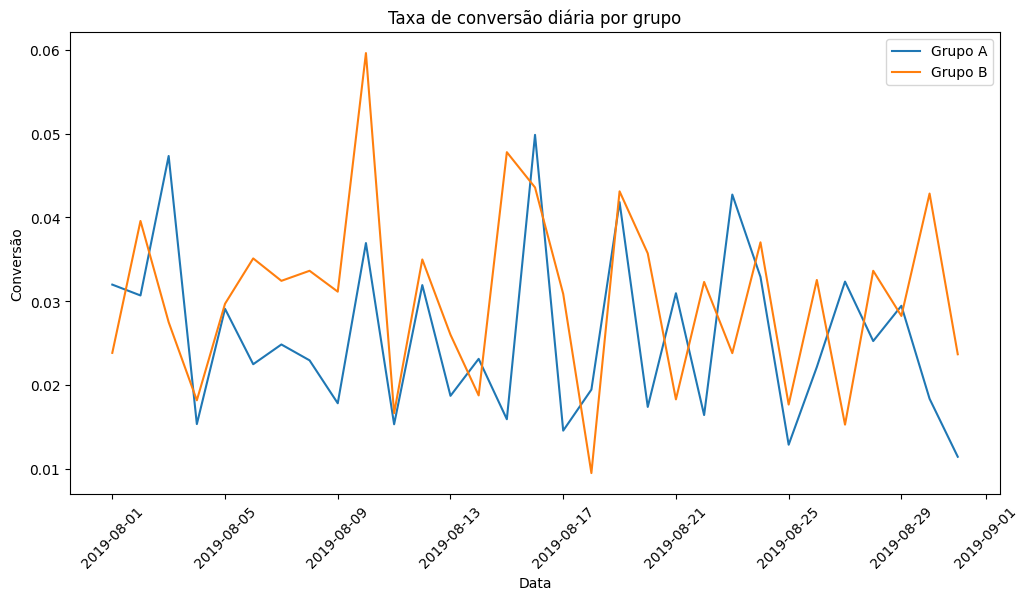

In [29]:
plt.figure(figsize=(12, 6))

plt.plot(
    conversion_A['date'],
    conversion_A['conversion'],
    label='Grupo A'
)

plt.plot(
    conversion_B['date'],
    conversion_B['conversion'],
    label='Grupo B'
)

plt.title('Taxa de conversão diária por grupo')
plt.xlabel('Data')
plt.ylabel('Conversão')

plt.legend()

plt.xticks(rotation=45)

plt.show()

Conclusão — Taxa de conversão diária por grupo

O gráfico de conversão diária mostra que os grupos A e B apresentaram comportamentos semelhantes ao longo do período analisado.

Nos primeiros dias do teste, entre 01/08 e 05/08, o grupo A apresentou uma conversão ligeiramente superior ao grupo B. Após esse período, os grupos permaneceram próximos, com pequenas variações diárias e alternância de liderança entre eles.

O grupo B apresentou uma conversão um pouco superior em diversos momentos do teste, porém a diferença entre os grupos não parece ser muito significativa visualmente. Também foi observado um pico de conversão do grupo B em aproximadamente 09/08, que pode representar uma variação pontual nos dados.

Dessa forma, o gráfico sugere uma possível vantagem do grupo B, mas será necessário realizar testes estatísticos para verificar se essa diferença é significativa ou apenas resultado de variações aleatórias.


In [30]:
cumulative_orders = (
    orders_filtered
    .groupby(['date', 'group'])
    .agg({'transactionId': 'nunique'})
    .reset_index()
)

cumulative_orders.columns = [
    'date',
    'group',
    'orders'
]

cumulative_orders = cumulative_orders.sort_values('date')

cumulative_orders['orders_cumulative'] = (
    cumulative_orders
    .groupby('group')['orders']
    .cumsum()
)

cumulative_orders.head()

,date,group,orders,orders_cumulative
0,2019-08-01,A,23,23
1,2019-08-01,B,17,17
2,2019-08-02,A,19,42
3,2019-08-02,B,23,40
4,2019-08-03,A,24,66


In [31]:
cumulative_visits = (
    visits
    .groupby(['date', 'group'])
    .agg({'visits': 'sum'})
    .reset_index()
)

cumulative_visits = cumulative_visits.sort_values('date')

cumulative_visits['visits_cumulative'] = (
    cumulative_visits
    .groupby('group')['visits']
    .cumsum()
)

cumulative_visits.head()

,date,group,visits,visits_cumulative
0,2019-08-01,A,719,719
1,2019-08-01,B,713,713
2,2019-08-02,A,619,1338
3,2019-08-02,B,581,1294
4,2019-08-03,A,507,1845


In [32]:
conversion_cumulative = cumulative_orders.merge(
    cumulative_visits[['date', 'group', 'visits_cumulative']],
    on=['date', 'group']
)

conversion_cumulative['conversion'] = (
    conversion_cumulative['orders_cumulative']
    / conversion_cumulative['visits_cumulative']
)

conversion_cumulative.head()

,date,group,orders,orders_cumulative,visits_cumulative,conversion
0,2019-08-01,A,23,23,719,0.031989
1,2019-08-01,B,17,17,713,0.023843
2,2019-08-02,A,19,42,1338,0.031390
3,2019-08-02,B,23,40,1294,0.030912
4,2019-08-03,A,24,66,1845,0.035772


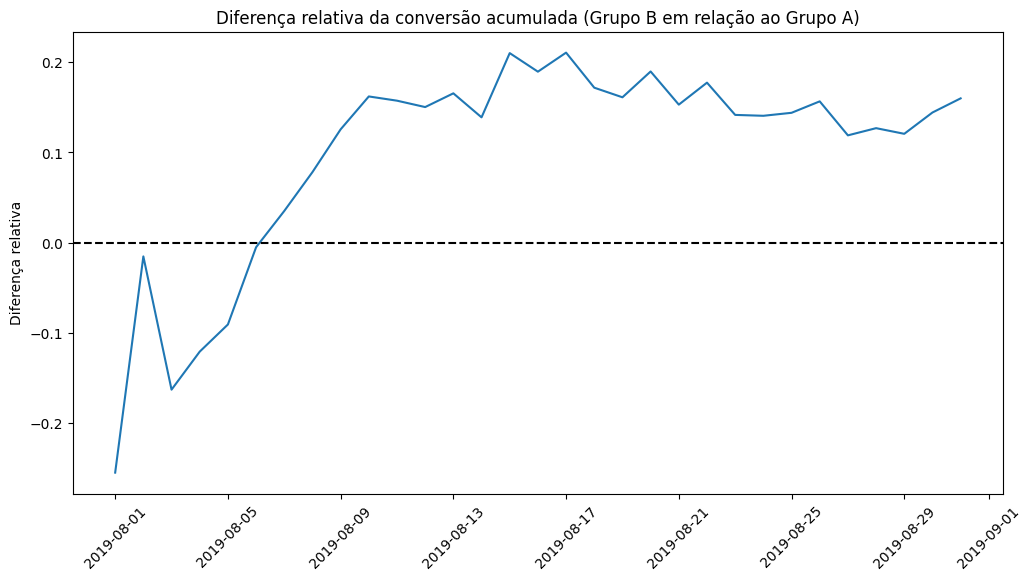

In [33]:
conversion_a = conversion_cumulative[
    conversion_cumulative['group'] == 'A'
][['date', 'conversion']]

conversion_b = conversion_cumulative[
    conversion_cumulative['group'] == 'B'
][['date', 'conversion']]

conversion_merged = conversion_a.merge(
    conversion_b,
    on='date',
    suffixes=('_A', '_B')
)

conversion_merged['relative_difference'] = (
    conversion_merged['conversion_B']
    / conversion_merged['conversion_A']
) - 1

plt.figure(figsize=(12, 6))

plt.plot(
    conversion_merged['date'],
    conversion_merged['relative_difference']
)

plt.axhline(y=0, color='black', linestyle='--')
plt.title('Diferença relativa da conversão acumulada (Grupo B em relação ao Grupo A)')
plt.ylabel('Diferença relativa')
plt.xticks(rotation=45)

plt.show()

Conclusão: A partir de aproximadamente 05/08/2019, a diferença relativa da conversão acumulada permanece acima de 0, indicando que o grupo B passou a apresentar uma taxa de conversão acumulada superior à do grupo A. Embora haja pequenas oscilações ao longo do período, a vantagem do grupo B se mantém relativamente estável até o final do teste. Isso sugere que a variante B teve um desempenho melhor em termos de conversão.

In [34]:
orders_by_users = (
    orders.groupby('visitorId')
    .agg({'transactionId': 'nunique'})
    .reset_index()
)

orders_by_users.columns = ['visitorId', 'orders']

print(np.percentile(orders_by_users['orders'], [95, 99]))

[2. 4.]


Conclusão: Os percentis mostram que 95% dos usuários realizaram até 2 pedidos e 99% realizaram até 4 pedidos. Como apenas uma pequena parcela dos usuários fez mais de 2 pedidos, esses casos podem ser considerados anomalias e filtrados nas análises posteriores.

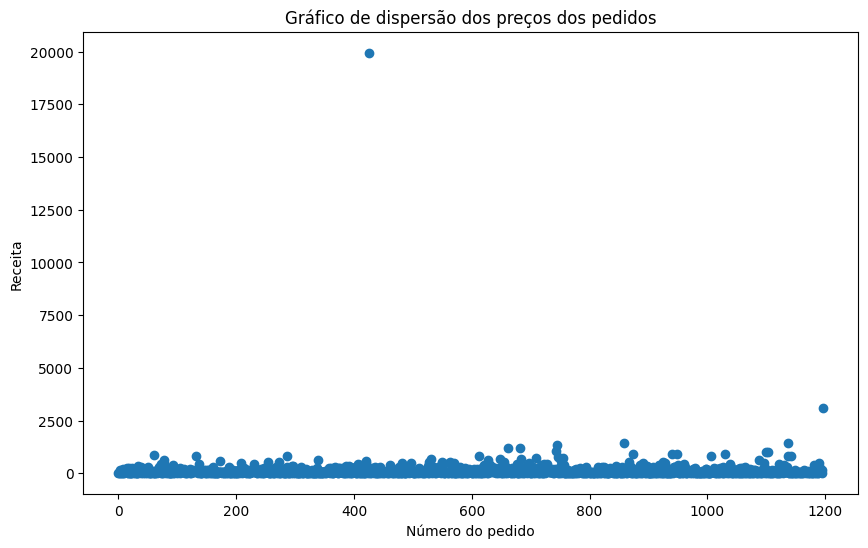

In [35]:
x_values = pd.Series(range(len(orders['revenue'])))

plt.figure(figsize=(10, 6))

plt.scatter(x_values, orders['revenue'])

plt.title('Gráfico de dispersão dos preços dos pedidos')
plt.xlabel('Número do pedido')
plt.ylabel('Receita')

plt.show()

Conclusão: O gráfico de dispersão mostra que a maior parte dos pedidos está concentrada em valores relativamente baixos, formando uma grande concentração de pontos. Também é possível observar alguns pedidos com valores significativamente mais altos e um pedido extremamente elevado, próximo de 20.000, caracterizando possíveis valores atípicos (outliers). Esses pedidos podem influenciar as métricas de receita e serão analisados por meio dos percentis para definir um limite de anomalia.

In [36]:
print(np.percentile(orders['revenue'], [95, 99]))

[435.54  900.904]


Conclusão: A análise dos percentis mostrou que 95% dos pedidos possuem receita de até 435,54 e 99% possuem receita de até 900,90. Como pedidos acima de 900,90 representam uma parcela muito pequena dos dados, esses valores podem ser considerados anomalias e serão removidos nas análises estatísticas filtradas.

In [37]:
orders_by_users = (
    orders.groupby(['group', 'visitorId'])
    .agg({'transactionId': 'nunique'})
    .reset_index()
)

orders_by_users.columns = [
    'group',
    'visitorId',
    'orders'
]

orders_by_users.head()

,group,visitorId,orders
0,A,8300375,1
1,A,11685486,1
2,A,54447517,1
3,A,66685450,1
4,A,78758296,1


In [38]:
id="6nq3v"
users_a = pd.concat(
    [
        orders_by_users[orders_by_users['group'] == 'A']['orders'],
        pd.Series(
            0,
            index=np.arange(
                visits[visits['group'] == 'A']['visits'].sum()
                - len(orders_by_users[orders_by_users['group'] == 'A'])
            )
        )
    ]
)

users_b = pd.concat(
    [
        orders_by_users[orders_by_users['group'] == 'B']['orders'],
        pd.Series(
            0,
            index=np.arange(
                visits[visits['group'] == 'B']['visits'].sum()
                - len(orders_by_users[orders_by_users['group'] == 'B'])
            )
        )
    ]
)

print('Conversão grupo A:', users_a.mean())
print('Conversão grupo B:', users_b.mean())

Conversão grupo A: 0.029728864218616567
Conversão grupo B: 0.033833791499259885


In [39]:
from scipy import stats

result = stats.mannwhitneyu(
    users_a,
    users_b
)

print('p-value:', result.pvalue)

p-value: 0.016792355056752608


Conclusão: O teste estatístico utilizando os dados brutos apresentou um p-value de aproximadamente 0,0168, menor que o nível de significância de 0,05. Portanto, rejeitamos a hipótese de que não existe diferença entre os grupos. Os resultados indicam uma diferença estatisticamente significativa na conversão, com o grupo B apresentando uma taxa de conversão superior ao grupo A.

In [40]:
print(
    'Tamanho médio do pedido grupo A:',
    orders[orders['group'] == 'A']['revenue'].mean()
)

print(
    'Tamanho médio do pedido grupo B:',
    orders[orders['group'] == 'B']['revenue'].mean()
)

Tamanho médio do pedido grupo A: 115.89748653500898
Tamanho médio do pedido grupo B: 145.06343750000002


In [41]:
from scipy import stats

result = stats.mannwhitneyu(
    orders[orders['group'] == 'A']['revenue'],
    orders[orders['group'] == 'B']['revenue']
)

print('p-value:', result.pvalue)

p-value: 0.6915246773264736


Conclusão: O grupo B apresentou um tamanho médio de pedido maior que o grupo A nos dados brutos (145,06 contra 115,90). No entanto, o teste estatístico apresentou um p-value de aproximadamente 0,6915, superior ao nível de significância de 0,05. Portanto, não há diferença estatisticamente significativa no tamanho médio dos pedidos entre os grupos. A diferença observada pode ser explicada pela presença de valores atípicos ou pela variação aleatória dos dados.

In [42]:
users_with_many_orders = (
    orders_by_users[orders_by_users['orders'] > 2]['visitorId']
)

users_with_many_orders.head()

18      199603092
23      237748145
68      611059232
146    1230306981
189    1614305549
Name: visitorId, dtype: int64

In [43]:
users_with_many_orders = orders_by_users[
    orders_by_users['orders'] > 2
]['visitorId']

users_with_expensive_orders = orders[
    orders['revenue'] > 900.90
]['visitorId']

abnormal_users = pd.concat(
    [
        users_with_many_orders,
        users_with_expensive_orders
    ]
).drop_duplicates()

orders_filtered_final = orders[
    ~orders['visitorId'].isin(abnormal_users)
]

orders_filtered_final.head()

,transactionId,visitorId,date,revenue,group
0,3667963787,3312258926,2019-08-15,30.4,B
1,2804400009,3642806036,2019-08-15,15.2,B
2,2961555356,4069496402,2019-08-15,10.2,A
3,3797467345,1196621759,2019-08-15,155.1,B
4,2282983706,2322279887,2019-08-15,40.5,B


In [44]:
orders_by_users_filtered = (
    orders_filtered_final
    .groupby(['group', 'visitorId'])
    .agg({'transactionId': 'nunique'})
    .reset_index()
)

orders_by_users_filtered.columns = [
    'group',
    'visitorId',
    'orders'
]

orders_by_users_filtered.head()

,group,visitorId,orders
0,A,8300375,1
1,A,11685486,1
2,A,54447517,1
3,A,66685450,1
4,A,78758296,1


In [45]:
users_a_filtered = pd.concat(
    [
        orders_by_users_filtered[
            orders_by_users_filtered['group'] == 'A'
        ]['orders'],
        pd.Series(
            0,
            index=np.arange(
                visits[visits['group'] == 'A']['visits'].sum()
                - len(
                    orders_by_users_filtered[
                        orders_by_users_filtered['group'] == 'A'
                    ]
                )
            )
        )
    ]
)

users_b_filtered = pd.concat(
    [
        orders_by_users_filtered[
            orders_by_users_filtered['group'] == 'B'
        ]['orders'],
        pd.Series(
            0,
            index=np.arange(
                visits[visits['group'] == 'B']['visits'].sum()
                - len(
                    orders_by_users_filtered[
                        orders_by_users_filtered['group'] == 'B'
                    ]
                )
            )
        )
    ]
)

print('Conversão grupo A filtrada:', users_a_filtered.mean())
print('Conversão grupo B filtrada:', users_b_filtered.mean())

Conversão grupo A filtrada: 0.026419726729291205
Conversão grupo B filtrada: 0.031031930640727425


In [46]:
result_filtered_conversion = stats.mannwhitneyu(
    users_a_filtered,
    users_b_filtered
)

print('p-value:', result_filtered_conversion.pvalue)

p-value: 0.0099697151782931


Conclusão: Após a remoção dos valores anômalos, o teste estatístico apresentou um p-value de aproximadamente 0,00997, inferior ao nível de significância de 0,05. Portanto, rejeitamos a hipótese de que não existe diferença entre os grupos. Os resultados indicam uma diferença estatisticamente significativa na conversão, com o grupo B apresentando uma taxa de conversão superior ao grupo A mesmo após a filtragem dos dados.

In [47]:
print(
    'Tamanho médio do pedido grupo A filtrado:',
    orders_filtered_final[
        orders_filtered_final['group'] == 'A'
    ]['revenue'].mean()
)

print(
    'Tamanho médio do pedido grupo B filtrado:',
    orders_filtered_final[
        orders_filtered_final['group'] == 'B'
    ]['revenue'].mean()
)

Tamanho médio do pedido grupo A filtrado: 103.47535353535355
Tamanho médio do pedido grupo B filtrado: 101.43952299829643


In [48]:
result_filtered_revenue = stats.mannwhitneyu(
    orders_filtered_final[
        orders_filtered_final['group'] == 'A'
    ]['revenue'],
    orders_filtered_final[
        orders_filtered_final['group'] == 'B'
    ]['revenue']
)

print('p-value:', result_filtered_revenue.pvalue)

p-value: 0.8448637528169688


Decisão: O teste A/B deve ser interrompido e o grupo B deve ser considerado o líder. A análise mostrou uma diferença estatisticamente significativa na conversão a favor do grupo B tanto nos dados brutos quanto nos dados filtrados. Embora não tenha sido identificada uma diferença estatisticamente significativa no tamanho médio dos pedidos, a melhora consistente na conversão indica que a alteração testada teve um efeito positivo no comportamento dos usuários.